<a href="https://colab.research.google.com/github/miriamamin1213-ux/AUC_Curves/blob/main/HancockGPT2Tab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Mounted at /content/drive
Rows with known target: 332
Class counts: {0: 191, 1: 141}
Train 215 {0: 123, 1: 92}
Validation 50 {0: 29, 1: 21}
Test 67 {0: 39, 1: 28}
Encoded input dimension: 19
Class weights: [0.87398374 1.16847826]


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Other trainable parameters: 116354


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | train=0.5863 | val=0.6013 | ROC-AUC=0.7365 | PR-AUC=0.6538 | balanced accuracy=0.7151
Epoch 100/500 | train=0.4848 | val=0.5845 | ROC-AUC=0.7496 | PR-AUC=0.7465 | balanced accuracy=0.7471
Epoch 150/500 | train=0.4495 | val=0.5636 | ROC-AUC=0.7709 | PR-AUC=0.7528 | balanced accuracy=0.7389
Epoch 200/500 | train=0.4240 | val=0.6416 | ROC-AUC=0.7611 | PR-AUC=0.7347 | balanced accuracy=0.7430
Epoch 250/500 | train=0.3491 | val=0.9603 | ROC-AUC=0.6954 | PR-AUC=0.6668 | balanced accuracy=0.6823
Epoch 300/500 | train=0.3286 | val=1.1056 | ROC-AUC=0.6708 | PR-AUC=0.6589 | balanced accuracy=0.6691
Epoch 350/500 | train=0.2710 | val=1.3958 | ROC-AUC=0.6773 | PR-AUC=0.6505 | balanced accuracy=0.6782
Epoch 400/500 | train=0.2525 | val=1.6540 | ROC-AUC=0.6379 | PR-AUC=0.5966 | balanced accuracy=0.6281
Epoch 450/500 | train=0.2430 | val=1.8618 | ROC-AUC=0.6149 | PR-AUC=0.5878 | balanced accuracy=0.6412
Epoch 500/500 | train=0.1826 | val=2.2067 | ROC-AUC=0.6232 | PR-AUC=0.5697 | balanc

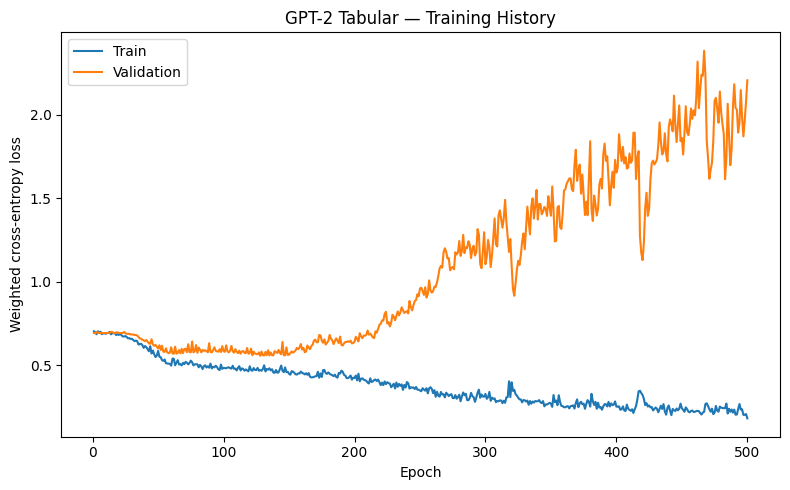


CHECKPOINT: best_val_loss | Epoch: 128
Checkpoint                      best_val_loss
Epoch                                     128
Threshold                            0.345092
Validation_Loss                      0.557112
Validation_ROC_AUC                   0.779146
Validation_PR_AUC                    0.754429
Validation_Balanced_Accuracy         0.773399
Balanced_Accuracy                    0.731227
F1                                   0.707692
ROC_AUC                              0.807692
PR_AUC                               0.782279
Confusion matrix:
 [[25 14]
 [ 5 23]]
              precision    recall  f1-score   support

HPV Negative     0.8333    0.6410    0.7246        39
HPV Positive     0.6216    0.8214    0.7077        28

    accuracy                         0.7164        67
   macro avg     0.7275    0.7312    0.7162        67
weighted avg     0.7449    0.7164    0.7176        67


CHECKPOINT: best_val_roc_auc | Epoch: 148
Checkpoint                      best_val_roc_a

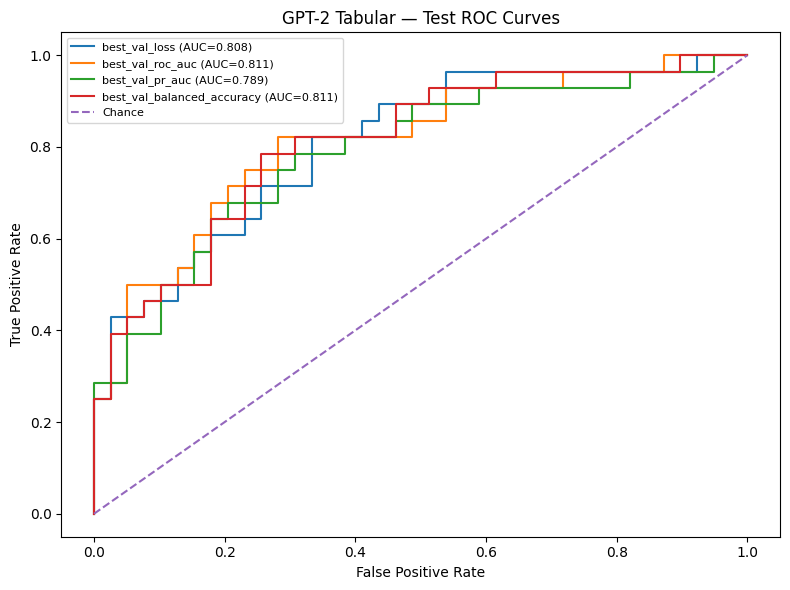

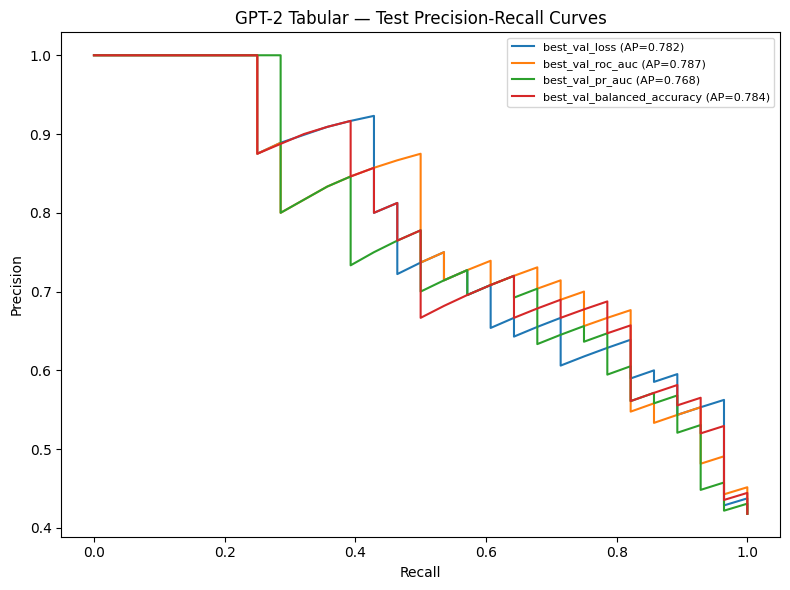

All results saved to: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results
Files: ['HANCOCK_GPT2_Tabular_Frozen_confidence_intervals.csv', 'checkpoints', 'metrics_all_checkpoints.csv', 'run_summary.json', 'tabular_preprocessor.joblib', 'test_pr_curves.png', 'test_predictions_all_checkpoints.csv', 'test_roc_curves.png', 'training_history.csv', 'training_history.png']


In [1]:

# HANCOCK HPV — GPT-2 TABULAR CLASSIFIER
# Matched protocol: clinical narrative reference
# 65/15/20 stratified split | Seed 42 | Batch 64 | 500 epochs
# No SMOTE | Four validation-selected checkpoints

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive
from transformers import GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
MODEL_NAME = "openai-community/gpt2"


# ============================================================
# 1. REPRODUCIBILITY AND DEVICE
# ============================================================

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "GPT2_Tabular_Hancock_Frozen_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD AND PREPARE DATA
# ============================================================

def load_json_table(path):
    with open(path, encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if isinstance(obj.get(key), list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table: {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)
pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError("clinical_data.json must contain patient_id.")

if "patient_id" not in pathology.columns:
    raise KeyError("pathological_data.json must contain patient_id.")

df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

target_col = next(
    (
        c for c in [
            "hpv_association_p16",
            "hpv_association_p16_path"
        ]
        if c in df.columns
    ),
    None
)

if target_col is None:
    raise KeyError("Could not find hpv_association_p16 target.")

feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for feature, candidates in feature_candidates.items():
    found = next(
        (c for c in candidates if c in df.columns),
        None
    )

    if found is None:
        raise KeyError(
            f"Missing predictor {feature}; checked {candidates}"
        )

    if found != feature:
        rename_map[found] = feature

df = df.rename(columns=rename_map)
features = list(feature_candidates)


def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()

print("Rows with known target:", len(df))
print(
    "Class counts:",
    df["HPV_Label"].value_counts().sort_index().to_dict()
)


# ============================================================
# 3. STRATIFIED 65/15/20 TRAIN/VALIDATION/TEST SPLIT
# ============================================================

train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train, val, test = [
    part.reset_index(drop=True)
    for part in (train, val, test)
]

for name, part in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        name,
        len(part),
        part["HPV_Label"].value_counts().sort_index().to_dict()
    )

X_train_df, X_val_df, X_test_df = [
    part[features].copy()
    for part in (train, val, test)
]

y_train, y_val, y_test = [
    part["HPV_Label"].to_numpy(dtype=np.int64)
    for part in (train, val, test)
]


# ============================================================
# 4. IMPUTATION AND ONE-HOT ENCODING
# ============================================================

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [
    c for c in features if c not in numeric_features
]

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = pd.to_numeric(
        frame["age_at_initial_diagnosis"],
        errors="coerce"
    )

age_median = X_train_df[
    "age_at_initial_diagnosis"
].median()

if pd.isna(age_median):
    age_median = 0.0

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = (
        frame["age_at_initial_diagnosis"].fillna(age_median)
    )

for col in categorical_features:
    modes = X_train_df[col].dropna().astype(str).mode()
    fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    for frame in (X_train_df, X_val_df, X_test_df):
        frame[col] = frame[col].fillna(fill_value)
        frame[col] = frame[col].astype(str).replace({
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown"
        })

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", encoder, categorical_features)
])

X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

print("Encoded input dimension:", X_train.shape[1])


# ============================================================
# 5. CLASS WEIGHTS — NO SMOTE
# ============================================================

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both classes must be present in training data."
    )

weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Class weights:", weights)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val, dtype=torch.float32, device=device
)
y_val_t = torch.tensor(
    y_val, dtype=torch.long, device=device
)
X_test_t = torch.tensor(
    X_test, dtype=torch.float32, device=device
)


# ============================================================
# 6. TABULAR GPT-2 ARCHITECTURE — PRESERVED
# ============================================================

class GPT2TabularClassifier(nn.Module):
    def __init__(self, n_features, dropout=0.1):
        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze all GPT-2 backbone parameters
        for param in self.gpt2.parameters():
            param.requires_grad = False

        hidden = self.gpt2.config.hidden_size
        self.feature_projection = nn.Linear(1, hidden)

        self.feature_embedding = nn.Parameter(
            torch.zeros(1, n_features, hidden)
        )
        nn.init.normal_(
            self.feature_embedding,
            mean=0.0,
            std=0.02
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Dropout(dropout),
            nn.Linear(hidden, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        tokens = self.feature_projection(x.unsqueeze(-1))
        tokens = tokens + self.feature_embedding

        hidden = self.gpt2(
            inputs_embeds=tokens
        ).last_hidden_state

        return self.classifier(hidden.mean(dim=1))


model = GPT2TabularClassifier(
    X_train.shape[1],
    DROPOUT
).to(device)
# VERIFY GPT-2 BACKBONE IS FROZEN
gpt2_trainable = sum(
    p.numel() for p in model.gpt2.parameters()
    if p.requires_grad
)

other_trainable = sum(
    p.numel() for name, p in model.named_parameters()
    if not name.startswith("gpt2.") and p.requires_grad
)

print("GPT-2 trainable parameters:", gpt2_trainable)
print("Other trainable parameters:", other_trainable)

assert gpt2_trainable == 0, "GPT-2 is NOT frozen!"
assert other_trainable > 0, "Tabular/classifier layers are NOT trainable!"



# Match clinical narrative weighted-loss calculation
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits,
        labels,
        reduction="none"
    )
    return (losses * class_weights[labels]).mean()


def evaluate_loss():
    model.eval()

    with torch.no_grad():
        return weighted_classification_loss(
            model(X_val_t),
            y_val_t
        ).item()


optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


def predict_probabilities(X_tensor):
    model.eval()

    with torch.no_grad():
        return torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()


# ============================================================
# 7. VALIDATION THRESHOLD AND METRICS
# ============================================================

def select_threshold(y_true, probabilities):
    thresholds = np.unique(
        np.concatenate(([0.0], probabilities, [1.0]))
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(
                y_true,
                (probabilities >= t).astype(int)
            )
        )
        for t in thresholds
    ]

    # Maximise balanced accuracy; ties closest to 0.5
    return max(
        results,
        key=lambda x: (x[1], -abs(x[0] - 0.5))
    )


def validation_metrics():
    p = predict_probabilities(X_val_t)
    threshold, bal_acc = select_threshold(y_val, p)

    roc_auc = (
        roc_auc_score(y_val, p)
        if len(np.unique(y_val)) == 2
        else np.nan
    )

    return {
        "threshold": float(threshold),
        "balanced_accuracy": float(bal_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(average_precision_score(y_val, p))
    }


checkpoint_specs = {
    "best_val_loss": (
        "gpt2_best_val_loss.pt", "min"
    ),
    "best_val_roc_auc": (
        "gpt2_best_val_roc_auc.pt", "max"
    ),
    "best_val_pr_auc": (
        "gpt2_best_val_pr_auc.pt", "max"
    ),
    "best_val_balanced_accuracy": (
        "gpt2_best_val_balanced_accuracy.pt", "max"
    )
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


# ============================================================
# 8. TRAIN — 500 EPOCHS
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    loss_sum = 0.0
    n_seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        loss = weighted_classification_loss(
            model(xb), yb
        )

        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(yb)
        n_seen += len(yb)

    train_loss = loss_sum / max(n_seen, 1)
    val_loss = evaluate_loss()
    vm = validation_metrics()

    history.append({
        "epoch": int(epoch),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": float(vm["roc_auc"]),
        "val_pr_auc": float(vm["pr_auc"]),
        "val_balanced_accuracy": float(vm["balanced_accuracy"]),
        "val_threshold": float(vm["threshold"])
    })

    scores = {
        "best_val_loss": val_loss,
        "best_val_roc_auc": vm["roc_auc"],
        "best_val_pr_auc": vm["pr_auc"],
        "best_val_balanced_accuracy": vm["balanced_accuracy"]
    }

    for key, score in scores.items():
        direction = checkpoint_specs[key][1]

        improved = (
            score < best_values[key]
            if direction == "min"
            else score > best_values[key]
        )

        if not np.isfinite(score) or not improved:
            continue

        best_values[key] = float(score)
        best_epochs[key] = int(epoch)

        # Store only standard Python scalar metadata.
        checkpoint_data = {
            "epoch": int(epoch),
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "validation_loss": float(val_loss),
            "validation_roc_auc": float(vm["roc_auc"]),
            "validation_pr_auc": float(vm["pr_auc"]),
            "validation_balanced_accuracy": float(
                vm["balanced_accuracy"]
            ),
            "validation_threshold": float(vm["threshold"])
        }

        torch.save(
            checkpoint_data,
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs[key][0]
            )
        )

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{MAX_EPOCHS} | "
            f"train={train_loss:.4f} | "
            f"val={val_loss:.4f} | "
            f"ROC-AUC={vm['roc_auc']:.4f} | "
            f"PR-AUC={vm['pr_auc']:.4f} | "
            f"balanced accuracy={vm['balanced_accuracy']:.4f}"
        )

if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs; ran {len(history)}."
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

print("Best checkpoint epochs:", best_epochs)

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy loss")
plt.title("GPT-2 Tabular — Training History")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)
plt.show()


# ============================================================
# 9. TEST EACH SELECTED CHECKPOINT
# ============================================================

all_metrics = []
all_predictions = []
test_probabilities = {}

for name, (filename, _) in checkpoint_specs.items():
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, filename
    )

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}. "
            "Run the training section first, or check Drive."
        )

    # FIX FOR PYTORCH 2.6+:
    # Use weights_only=False only for trusted checkpoints
    # generated by this notebook.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    val_prob = predict_probabilities(X_val_t)
    test_prob = predict_probabilities(X_test_t)
    test_probabilities[name] = test_prob

    # Select threshold from validation data only.
    threshold, val_bal_acc = select_threshold(
        y_val, val_prob
    )

    test_pred = (test_prob >= threshold).astype(int)

    test_roc_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_pr_auc = average_precision_score(
        y_test, test_prob
    )

    metrics = {
        "Checkpoint": name,
        "Epoch": int(checkpoint["epoch"]),
        "Threshold": float(threshold),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Balanced_Accuracy": float(
            balanced_accuracy_score(y_test, test_pred)
        ),
        "F1": float(
            f1_score(y_test, test_pred, zero_division=0)
        ),
        "ROC_AUC": float(test_roc_auc),
        "PR_AUC": float(test_pr_auc)
    }

    all_metrics.append(metrics)

    all_predictions.append(pd.DataFrame({
        "patient_id": test["patient_id"].to_numpy(),
        "y_true": y_test,
        "probability_positive": test_prob,
        "prediction": test_pred,
        "checkpoint": name,
        "epoch": int(checkpoint["epoch"]),
        "threshold": float(threshold)
    }))

    print("\n", "=" * 55)
    print("CHECKPOINT:", name, "| Epoch:", checkpoint["epoch"])
    print(pd.Series(metrics).to_string())

    print(
        "Confusion matrix:\n",
        confusion_matrix(y_test, test_pred, labels=[0, 1])
    )

    print(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

pd.DataFrame(all_metrics).to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    os.path.join(
        OUT_DIR,
        "test_predictions_all_checkpoints.csv"
    ),
    index=False
)


# ============================================================
# 10. TEST ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    if len(np.unique(y_test)) < 2:
        continue

    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GPT-2 Tabular — Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_roc_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 11. TEST PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)

    plt.plot(
        recall, precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("GPT-2 Tabular — Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_pr_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 12. SAVE PREPROCESSOR AND RUN SUMMARY
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "tabular_preprocessor.joblib")
)

summary = {
    "seed": SEED,
    "model_name": MODEL_NAME,
    "epochs": MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "original_predictors": features,
    "encoded_feature_count": int(X_train.shape[1]),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "smote": False,
    "gradient_clipping": False,
    "gpt2_fine_tuned": True,
    "class_weights": [
        float(w) for w in class_weights.detach().cpu().tolist()
    ],
    "checkpoint_selection": (
        "Best validation loss, ROC-AUC, PR-AUC "
        "and balanced accuracy"
    ),
    "threshold_selection": (
        "Maximise validation balanced accuracy over unique "
        "scores plus 0 and 1; ties closest to 0.5"
    ),
    "loss": (
        "Mean per-example cross-entropy multiplied "
        "by target-class weight"
    ),
    "best_epochs": {
        k: int(v) for k, v in best_epochs.items()
    }
}

with open(
    os.path.join(OUT_DIR, "run_summary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("All results saved to:", OUT_DIR)
print("Files:", sorted(os.listdir(OUT_DIR)))


Selected checkpoint: best_val_roc_auc
Epoch: 148
Test patients: 67
Validation-selected threshold: 0.257873922586441

Point estimates:
ROC_AUC: 0.8114
PR_AUC: 0.7865
Balanced_Accuracy: 0.7697
Sensitivity: 0.8214
Specificity: 0.7179
F1_Score: 0.7419

95% CONFIDENCE INTERVALS


,Checkpoint,Epoch,Metric,Estimate,CI_95_Lower,CI_95_Upper,Bootstrap_Replicates
0,best_val_roc_auc,148,ROC_AUC,0.8114,0.6996,0.9084,5000
1,best_val_roc_auc,148,PR_AUC,0.7865,0.6682,0.8965,5000
2,best_val_roc_auc,148,Balanced_Accuracy,0.7697,0.6648,0.8645,5000
3,best_val_roc_auc,148,Sensitivity,0.8214,0.6786,0.9643,5000
4,best_val_roc_auc,148,Specificity,0.7179,0.5641,0.8462,5000
5,best_val_roc_auc,148,F1_Score,0.7419,0.6333,0.8421,5000



ROC-AUC: 0.8114 (95% CI 0.6996–0.9084)


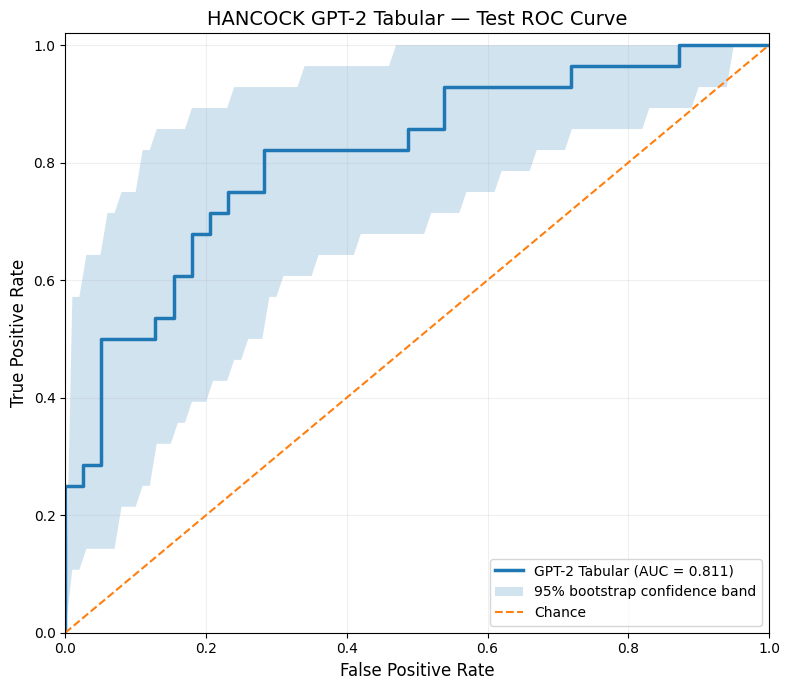


Files saved:
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/HANCOCK_GPT2_Tabular_ROC_CI.csv
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/HANCOCK_GPT2_Tabular_ROC_Curve_CI.png
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/HANCOCK_GPT2_Tabular_ROC_AUC_Summary.csv


In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve
)

# =========================================================
# 1. FILE PATHS AND SELECTED CHECKPOINT
# =========================================================

OUT_DIR = (
    "/content/drive/MyDrive/"
    "GPT2_Tabular_Hancock_Frozen_results"
)

PREDICTION_FILE = os.path.join(
    OUT_DIR,
    "test_predictions_all_checkpoints.csv"
)

CHECKPOINT = "best_val_roc_auc"
N_BOOTSTRAPS = 5000
RANDOM_SEED = 42

CI_FILE = os.path.join(
    OUT_DIR,
    "HANCOCK_GPT2_Tabular_ROC_CI.csv"
)

ROC_FIGURE = os.path.join(
    OUT_DIR,
    "HANCOCK_GPT2_Tabular_ROC_Curve_CI.png"
)

# =========================================================
# 2. LOAD THE SELECTED TEST PREDICTIONS
# =========================================================

df = pd.read_csv(PREDICTION_FILE)

selected = df[
    df["checkpoint"] == CHECKPOINT
].copy()

selected = selected.sort_values("patient_id")

assert len(selected) == 67
assert selected["patient_id"].nunique() == 67

y_true = selected["y_true"].astype(int).to_numpy()
y_prob = selected[
    "probability_positive"
].astype(float).to_numpy()

threshold = float(
    selected["threshold"].iloc[0]
)

y_pred = (y_prob >= threshold).astype(int)

print("Selected checkpoint:", CHECKPOINT)
print("Epoch:", int(selected["epoch"].iloc[0]))
print("Test patients:", len(y_true))
print("Validation-selected threshold:", threshold)

# =========================================================
# 3. POINT ESTIMATES
# =========================================================

def calculate_metrics(y, probabilities, predictions):

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(y, probabilities),
        "PR_AUC": average_precision_score(
            y, probabilities
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y, predictions
        ),
        "Sensitivity": recall_score(
            y, predictions, pos_label=1,
            zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "F1_Score": f1_score(
            y, predictions, zero_division=0
        )
    }

point_estimates = calculate_metrics(
    y_true, y_prob, y_pred
)

print("\nPoint estimates:")
for metric, value in point_estimates.items():
    print(f"{metric}: {value:.4f}")

# =========================================================
# 4. STRATIFIED BOOTSTRAP CONFIDENCE INTERVALS
# =========================================================

rng = np.random.default_rng(RANDOM_SEED)

positive_indices = np.where(y_true == 1)[0]
negative_indices = np.where(y_true == 0)[0]

bootstrap_results = {
    metric: [] for metric in point_estimates
}

# Also store ROC curves for the confidence band
fpr_grid = np.linspace(0, 1, 101)
bootstrap_tprs = []
bootstrap_auc = []

for i in range(N_BOOTSTRAPS):

    boot_pos = rng.choice(
        positive_indices,
        size=len(positive_indices),
        replace=True
    )

    boot_neg = rng.choice(
        negative_indices,
        size=len(negative_indices),
        replace=True
    )

    boot_indices = np.concatenate(
        [boot_pos, boot_neg]
    )

    boot_y = y_true[boot_indices]
    boot_prob = y_prob[boot_indices]
    boot_pred = (boot_prob >= threshold).astype(int)

    # Metric confidence intervals
    metrics = calculate_metrics(
        boot_y, boot_prob, boot_pred
    )

    for metric, value in metrics.items():
        bootstrap_results[metric].append(value)

    # ROC curve confidence intervals
    fpr, tpr, _ = roc_curve(
        boot_y, boot_prob
    )

    auc_value = roc_auc_score(
        boot_y, boot_prob
    )

    interpolated_tpr = np.interp(
        fpr_grid, fpr, tpr
    )

    interpolated_tpr[0] = 0.0

    bootstrap_tprs.append(interpolated_tpr)
    bootstrap_auc.append(auc_value)

# =========================================================
# 5. CALCULATE 95% CONFIDENCE INTERVALS
# =========================================================

results = []

for metric, estimate in point_estimates.items():

    values = np.asarray(
        bootstrap_results[metric]
    )

    values = values[np.isfinite(values)]

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)

    results.append({
        "Checkpoint": CHECKPOINT,
        "Epoch": 148,
        "Metric": metric,
        "Estimate": estimate,
        "CI_95_Lower": lower,
        "CI_95_Upper": upper,
        "Bootstrap_Replicates": len(values)
    })

# ROC-AUC CI
auc_lower = np.percentile(bootstrap_auc, 2.5)
auc_upper = np.percentile(bootstrap_auc, 97.5)

ci_df = pd.DataFrame(results)

ci_df.to_csv(CI_FILE, index=False)

print("\n95% CONFIDENCE INTERVALS")
display(ci_df.round(4))

print(
    f"\nROC-AUC: {point_estimates['ROC_AUC']:.4f} "
    f"(95% CI {auc_lower:.4f}–{auc_upper:.4f})"
)

# =========================================================
# 6. ROC CURVE WITH 95% BOOTSTRAP CONFIDENCE BAND
# =========================================================

fpr, tpr, _ = roc_curve(y_true, y_prob)

mean_tpr = np.mean(
    bootstrap_tprs, axis=0
)

lower_tpr = np.percentile(
    bootstrap_tprs, 2.5, axis=0
)

upper_tpr = np.percentile(
    bootstrap_tprs, 97.5, axis=0
)

# Ensure conventional ROC endpoints
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
lower_tpr[0] = 0.0
upper_tpr[0] = 0.0
lower_tpr[-1] = 1.0
upper_tpr[-1] = 1.0

plt.figure(figsize=(8, 7))

plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=(
        f"GPT-2 Tabular "
        f"(AUC = {point_estimates['ROC_AUC']:.3f})"
    )
)

plt.fill_between(
    fpr_grid,
    lower_tpr,
    upper_tpr,
    alpha=0.20,
    label="95% bootstrap confidence band"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Chance"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "HANCOCK GPT-2 Tabular — Test ROC Curve",
    fontsize=14
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    ROC_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 7. SAVE ROC-AUC CONFIDENCE INTERVAL SUMMARY
# =========================================================

roc_summary = pd.DataFrame([{
    "Model": "HANCOCK GPT-2 Tabular",
    "Checkpoint": CHECKPOINT,
    "Epoch": 148,
    "Test_ROC_AUC": point_estimates["ROC_AUC"],
    "ROC_AUC_CI_95_Lower": auc_lower,
    "ROC_AUC_CI_95_Upper": auc_upper,
    "Bootstrap_Replicates": N_BOOTSTRAPS
}])

roc_summary.to_csv(
    os.path.join(
        OUT_DIR,
        "HANCOCK_GPT2_Tabular_ROC_AUC_Summary.csv"
    ),
    index=False
)

print("\nFiles saved:")
print(CI_FILE)
print(ROC_FIGURE)
print(
    os.path.join(
        OUT_DIR,
        "HANCOCK_GPT2_Tabular_ROC_AUC_Summary.csv"
    )
)


Selected checkpoint: best_val_roc_auc
Epoch: 148
Test patients: 67
Test ROC-AUC: 0.8114


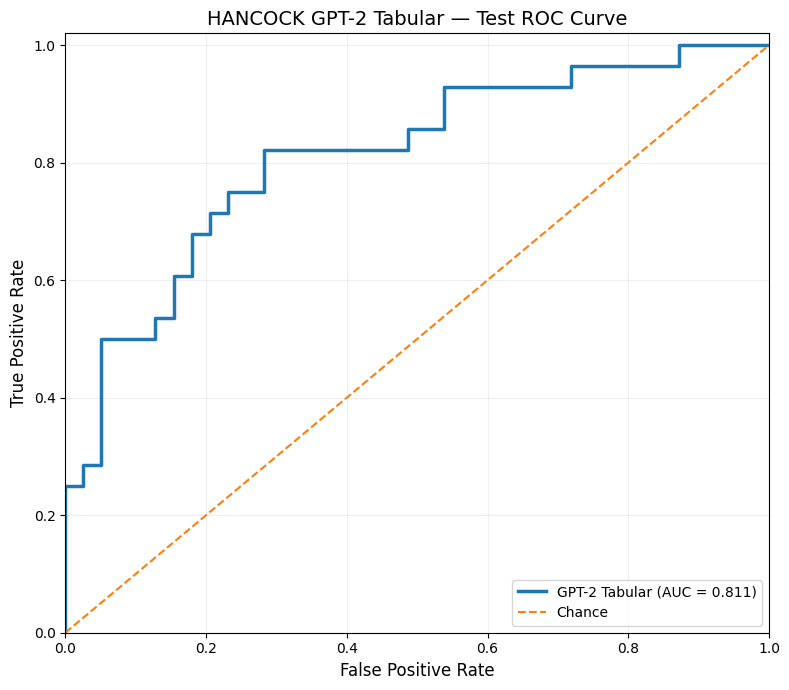

ROC curve saved to:
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/HANCOCK_GPT2_Tabular_Test_ROC_Curve.png


In [3]:

import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# ==========================================
# 1. LOAD SELECTED CHECKPOINT PREDICTIONS
# ==========================================

OUT_DIR = (
    "/content/drive/MyDrive/"
    "GPT2_Tabular_Hancock_Frozen_results"
)

PREDICTION_FILE = os.path.join(
    OUT_DIR,
    "test_predictions_all_checkpoints.csv"
)

df = pd.read_csv(PREDICTION_FILE)

# Select the validation ROC-AUC checkpoint
selected = df[
    df["checkpoint"] == "best_val_roc_auc"
].copy()

y_true = selected["y_true"].astype(int)
y_prob = selected["probability_positive"].astype(float)

# ==========================================
# 2. CALCULATE ROC CURVE AND AUC
# ==========================================

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

print("Selected checkpoint: best_val_roc_auc")
print("Epoch:", int(selected["epoch"].iloc[0]))
print("Test patients:", len(selected))
print(f"Test ROC-AUC: {roc_auc:.4f}")

# ==========================================
# 3. PLOT ROC CURVE
# ==========================================

plt.figure(figsize=(8, 7))

plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"GPT-2 Tabular (AUC = {roc_auc:.3f})"
)

# Chance diagonal
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Chance"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "HANCOCK GPT-2 Tabular — Test ROC Curve",
    fontsize=14
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()

# Save high-resolution figure
ROC_FILE = os.path.join(
    OUT_DIR,
    "HANCOCK_GPT2_Tabular_Test_ROC_Curve.png"
)

plt.savefig(
    ROC_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved to:")
print(ROC_FILE)


Selected checkpoint: best_val_roc_auc
Epoch: 148
Test patients: 67
Test PR-AUC (Average Precision): 0.7865


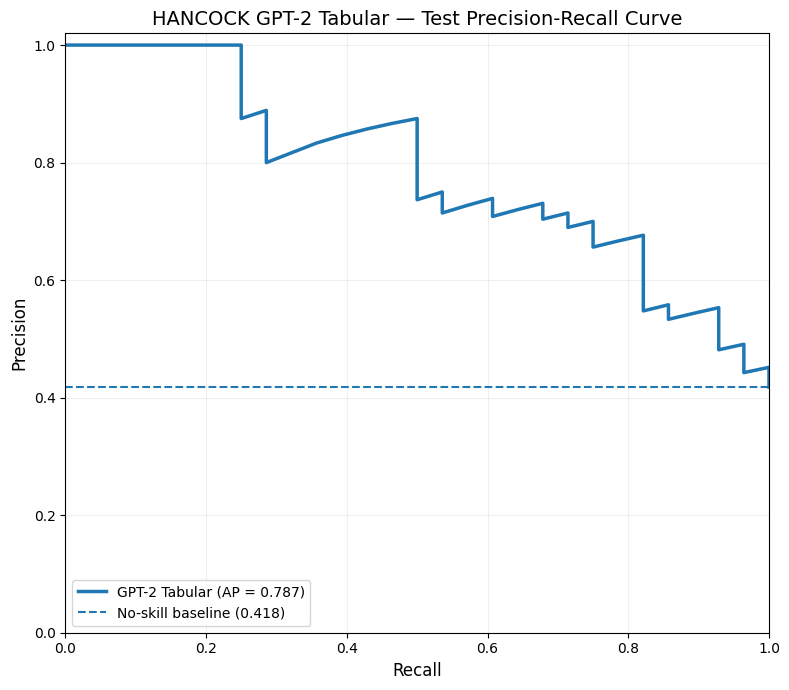

PR curve saved to:
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/HANCOCK_GPT2_Tabular_Test_PR_Curve.png


In [4]:

import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ==========================================
# 1. LOAD SELECTED CHECKPOINT PREDICTIONS
# ==========================================

OUT_DIR = (
    "/content/drive/MyDrive/"
    "GPT2_Tabular_Hancock_Frozen_results"
)

PREDICTION_FILE = os.path.join(
    OUT_DIR,
    "test_predictions_all_checkpoints.csv"
)

df = pd.read_csv(PREDICTION_FILE)

# Select validation ROC-AUC checkpoint
selected = df[
    df["checkpoint"] == "best_val_roc_auc"
].copy()

y_true = selected["y_true"].astype(int)
y_prob = selected["probability_positive"].astype(float)

# ==========================================
# 2. CALCULATE PRECISION-RECALL CURVE
# ==========================================

precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_prob
)

pr_auc = average_precision_score(
    y_true,
    y_prob
)

print("Selected checkpoint: best_val_roc_auc")
print("Epoch:", int(selected["epoch"].iloc[0]))
print("Test patients:", len(selected))
print(f"Test PR-AUC (Average Precision): {pr_auc:.4f}")

# ==========================================
# 3. PLOT PR CURVE
# ==========================================

plt.figure(figsize=(8, 7))

plt.plot(
    recall,
    precision,
    linewidth=2.5,
    label=f"GPT-2 Tabular (AP = {pr_auc:.3f})"
)

# No-skill baseline: proportion of positive cases
positive_prevalence = y_true.mean()

plt.axhline(
    y=positive_prevalence,
    linestyle="--",
    linewidth=1.5,
    label=f"No-skill baseline ({positive_prevalence:.3f})"
)

plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)

plt.title(
    "HANCOCK GPT-2 Tabular — Test Precision-Recall Curve",
    fontsize=14
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(loc="lower left")
plt.grid(alpha=0.2)
plt.tight_layout()

# ==========================================
# 4. SAVE HIGH-RESOLUTION FIGURE
# ==========================================

PR_FILE = os.path.join(
    OUT_DIR,
    "HANCOCK_GPT2_Tabular_Test_PR_Curve.png"
)

plt.savefig(
    PR_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR curve saved to:")
print(PR_FILE)
